<a href="https://colab.research.google.com/github/jnolorbe/hydrology-peru/blob/main/notebooks/04_insitu_validation_seasonality_and_enso_regimes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04. Independent In-Situ Validation of GRACE-Derived Seasonality and ENSO Regimes (E / C Indices)

**Project:** Spatio-temporal Analysis of Hydrological Response in Peru (2002–2025)

**Author:** Prof. Juan Mendoza-Nolorbe

**Affiliation:** Universidad Nacional Mayor de San Marcos (UNMSM)

**Phase 4:** Independent Validation Against In-Situ Hydrometeorological Records

---

### Overview: Validation Pipeline

Notebooks 02 and 03 established two central findings from GRACE/GRACE-FO Terrestrial Water
Storage (TWS) anomalies: (i) a robust **annual seasonal climatology** per Administrative
Hydrographic Domain (AAA), and (ii) a **differentiated TWS response to the two ENSO "flavours"**
described by the IGP E and C indices (Takahashi et al., 2011):

* **E index — extreme Eastern Pacific El Niño** (extreme warm events in the eastern Pacific; R = 0.94 with Niño 1+2). Its warm extreme (El Niño E, `E ≥ 1.0 & C < 1.0`)
  produces the strongest and most coherent signature: a **storage surplus in north-western Peru**.
* **C index — Central Pacific** (cold and moderate warm events; R = 0.98 with Niño 4). The C index is *not* a La Niña index: its
  **positive** phase is the Central Pacific El Niño (El Niño C, `C ≥ 0.5 & E < 0.5`),
  and only its **negative** extreme corresponds to the Central Pacific La Niña
  (La Niña C, `C ≤ −1.0`). Cai et al. (2020, Fig. 3) use exactly this convention
  (CP El Niño: C > +1 s.d.; CP La Niña: C < −1 s.d.).

Following Takahashi et al. (2011), E and C do not describe two distinct phenomena (canonical vs. "Modoki" El Niño) but two regimes of the nonlinear evolution of ENSO. The regimes are therefore named by region — **El Niño E (Eastern Pacific)** and **El Niño C (Central Pacific)** — and *coastal El Niño* is reserved for events defined by the ENFEN ICEN (e.g. 2017, 2023–24). The E regime is not equivalent to the coastal El Niño (the 2017 coastal event does not reach E ≥ 1.0 with ERSSTv5).

This notebook cross-validates these findings against an independent, previously standardized
collection of **in-situ streamflow (caudal) and precipitation records** for Peruvian basins,
compiled and quality-controlled outside of this GRACE pipeline. Because the in-situ record and
the GRACE record (2002–2025) are largely **non-overlapping in time** for many stations, this is
a genuine independent test of the satellite-derived signal rather than a same-period
cross-check: it asks whether an entirely different observation system, over different decades,
reproduces the same physical pattern.

Two objectives are addressed:

1. **Seasonality consistency (Section III):** does the mean annual in-situ climatology
   (caudal/precipitation) peak and trough in phase with the GRACE TWS climatology of the
   same AAA domain?
2. **ENSO regime consistency (Section IV):** does the in-situ record reproduce the same
   sign of anomaly, domain by domain, that GRACE shows for the **same three regimes defined in
   Notebook 03**: El Niño E (Eastern Pacific, headline result), **El Niño C (Central Pacific)**,
   and La Niña C (Central Pacific La Niña, the cold phase of the C index).

# I. Introduction and Data Provenance

## 1.1. Motivation

GRACE/GRACE-FO mascon TWS anomalies are a powerful but indirect proxy for terrestrial water
storage: they integrate soil moisture, groundwater, snow, and surface water over ~300 km
footprints and cannot be verified by a single ground instrument. Independent validation against
conventional, point-based hydrometeorological monitoring (river discharge and precipitation
gauges) is the standard way to build confidence that the coarse-resolution satellite signal
reflects real, ground-observable hydrological behaviour rather than a processing artefact.

## 1.2. The In-Situ Dataset

The validation dataset consists of 64 standardized in-situ time series (streamflow and
precipitation, `data/insitu/` in this repository), each accompanied by a metadata file
(`.md`) documenting station coordinates, source, record period, and standardization method.
Every file was assigned to one of the 14 AAA hydrographic domains using a basin-name heuristic
cross-validated against a geopandas point-in-polygon test on the station coordinates (see
`data/insitu/insitu_index.csv` for the per-file domain assignment and its confidence level).
The analysis uses **64 datasets**.

## 1.3. Non-Overlapping Periods — Why This Still Works

Most in-situ records pre-date the GRACE mission (2002–present) or only partially overlap it.
This notebook does **not** attempt a synchronous, month-to-month correlation between GRACE and
in-situ time series (that would require temporal overlap that does not exist for most
stations). Instead it compares **climatological summaries** that are, by construction, stable
descriptors of the annual cycle and of the ENSO response, and can legitimately be compared
across non-concurrent periods:

* the **mean annual cycle** (Section III), and
* the **standardized composite anomaly during classified ENSO phases** (Section IV), where
  ENSO phase is assigned **month by month from the IGP E/C index computed from ERSSTv6**, a
  single homogeneous series covering the whole in-situ period since 1950 (Section 2.5 and
  Section IV.2).

# II. Environment Setup and Data Loading

In [1]:
# =================================================================
# 2.1. LIBRARY INSTALLATION AND CORE ENVIRONMENT SETUP
# =================================================================
# Secure, idempotent installation compatible with Google Colab and JupyterHub
!pip install --quiet cmcrameri netCDF4 xarray rioxarray geopandas shapely openpyxl statsmodels

import os
import re
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl
import rioxarray  # noqa: F401 — registers .rio accessor on xarray objects
import cmcrameri.cm as cmc

from statsmodels.tsa.seasonal import seasonal_decompose

print("✓ All libraries imported successfully.")

✓ All libraries imported successfully.


In [2]:
# =================================================================
# 2.2. REPOSITORY SYNCHRONIZATION AND DATAPATH ARCHITECTURE
# =================================================================
REPO_NAME = "hydrology-peru"
GITHUB_USERNAME = "jnolorbe"  # Update if forking
REPO_URL = f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"

if not os.path.exists(REPO_NAME):
    print(f"Cloning climate repository from {REPO_URL}...")
    !git clone {REPO_URL}
else:
    print("Repository existing. Pulling latest data changes...")
    %cd {REPO_NAME}
    !git pull
    %cd ..

# Establish explicit paths to raw and processed data assets
DATA_PATH = os.path.join(REPO_NAME, "data")
SHP_PATH = os.path.join(REPO_NAME, "data/shapefiles")

TWS_FILE = os.path.join(DATA_PATH, "processed/GRACE_Peru_final_IQR1_5.nc")
ENSO_FILE = os.path.join(DATA_PATH, "enso/ecindex_ersstv5.csv")                    # IGP E/C, ERSSTv5, 2002+ (Notebook 03)
ENSO_V6_FILE = os.path.join(DATA_PATH, "enso/ecindex_ersstv6.csv")                 # IGP E/C, ERSSTv6, 1850–present
SHP_AAA_FILE = os.path.join(SHP_PATH, "hydroAAA_domains/Autoridad_Administrativa_del_Agua.shp")
INSITU_PATH = os.path.join(DATA_PATH, "insitu")
INSITU_INDEX_FILE = os.path.join(INSITU_PATH, "insitu_index.csv")

print("✓ Path architecture and synchronization complete.")

Repository existing. Pulling latest data changes...
/home/claude/tr/run/hydrology-peru
/home/claude/tr/run
✓ Path architecture and synchronization complete.


In [3]:
# =================================================================
# 2.3. INGESTION AND BASELINE CENTERING OF RASTER DATA
# =================================================================
if not os.path.exists(TWS_FILE):
    raise FileNotFoundError(f"Missing required NetCDF file at: {TWS_FILE}")

xr_grace = xr.open_dataset(TWS_FILE)

xr_grace.attrs.update({
    "long_name": "Equivalent Water Height",
    "units": "cm",
    "crs": "+proj=longlat +datum=WGS84",
    "ellipsoid": "WGS84",
    "res": (0.5, 0.5),
    "nodatavals": "nan",
})

if 'month' in xr_grace:
    xr_grace = xr_grace.drop_vars('month')

# Compute long-term temporal baseline mean to generate centered TWS anomalies
long_term_mean = xr_grace['lwe_thickness_corrected'].mean('time')
xr_grace['lwe_thickness_centered'] = xr_grace['lwe_thickness_corrected'] - long_term_mean
xr_grace['lwe_thickness_centered'].attrs.update({
    'long_name': 'TWS Anomaly (mean-centred)',
    'units': 'cm'
})

xr_grace = xr_grace.rio.write_crs("EPSG:4326")
print(f"✓ GRACE raster ingested. Time steps: {len(xr_grace.time)} months.")

✓ GRACE raster ingested. Time steps: 288 months.


In [4]:
# =================================================================
# 2.4. VECTOR DATASET INGESTION (14 AAA HYDROGRAPHIC DOMAINS)
# =================================================================
gdf_aaa = gpd.read_file(SHP_AAA_FILE)
if gdf_aaa.crs.to_epsg() != 4326:
    gdf_aaa = gdf_aaa.to_crs(epsg=4326)

# Drop small fragments of the Ucayali domain to prevent spatial leaks (as in Notebook 03)
gdf_aaa = gdf_aaa[~((gdf_aaa['NAME_AAA'] == 'UCAYALI') & (gdf_aaa['OBJECTID_1'].isin([10, 11])))]

REGION_ORDER = [
    'JEQUETEPEQUE-ZARUMILLA', 'HUARMEY-CHICAMA', 'MARAÑÓN', 'HUALLAGA',
    'AMAZONAS', 'CAÑETE-FORTALEZA', 'MANTARO', 'CHÁPARRA-CHINCHA',
    'UCAYALI', 'PAMPAS-APURIMAC', 'URUBAMBA-VILCANOTA', 'MADRE DE DIOS',
    'CAPLINA-OCOÑA', 'TITICACA'
]

print(f"✓ Vector assets loaded. AAA Hydrographic Domains available: {len(gdf_aaa)}")

✓ Vector assets loaded. AAA Hydrographic Domains available: 14


In [5]:
# =================================================================
# 2.5. ENSO INDEX INGESTION — IGP E/C INDICES (Takahashi et al., 2011; no smoothing)
# =================================================================
#   * ENSO_FILE    : ERSSTv5 version, 2002-01 → present. Used ONLY for the GRACE composites,
#                    so they stay identical to Notebook 03 (the result being validated).
#   * ENSO_V6_FILE : ERSSTv6 version, 1850-01 → present, same format as ENSO_FILE
#                    (time = YYYY-MM-01, E_index, C_index). Used for the month-by-month classification
#                    of the in-situ records, from 1950 onward, as one homogeneous series.
for fp in (ENSO_FILE, ENSO_V6_FILE):
    if not os.path.exists(fp):
        raise FileNotFoundError(f"Missing required IGP index file at: {fp}")

df_ec_v5 = pd.read_csv(ENSO_FILE)
df_ec_v5.columns = [c.strip().lower() for c in df_ec_v5.columns]
df_ec_v5['time'] = pd.to_datetime(pd.to_datetime(df_ec_v5['time']).values.astype('datetime64[M]'))
df_ec_v5 = df_ec_v5.set_index('time').sort_index()[['e_index', 'c_index']]

df_ec_v6 = pd.read_csv(ENSO_V6_FILE)
df_ec_v6.columns = [c.strip().lower() for c in df_ec_v6.columns]
df_ec_v6['time'] = pd.to_datetime(pd.to_datetime(df_ec_v6['time']).values.astype('datetime64[M]'))
df_ec_v6 = df_ec_v6.set_index('time').sort_index()[['e_index', 'c_index']]
assert not df_ec_v6.index.duplicated().any() and df_ec_v6.notna().all().all()


def regime_labels(df):
    """Notebook 03 thresholds, vectorised (used for the consistency check only)."""
    e, c = df['e_index'], df['c_index']
    lab = pd.Series('unclassified', index=df.index)
    lab[(e >= 1.0) & (c < 1.0)] = 'nino_e'
    lab[(c >= 0.5) & (e < 0.5)] = 'nino_c'
    lab[c <= -1.0] = 'nina_c'
    lab[(e.abs() < 0.5) & (c.abs() < 0.5)] = 'neutral'
    return lab


# --- Consistency check ERSSTv6 vs. ERSSTv5 over their common period ---
overlap = df_ec_v6.index.intersection(df_ec_v5.index)
r_E = df_ec_v6.loc[overlap, 'e_index'].corr(df_ec_v5.loc[overlap, 'e_index'])
r_C = df_ec_v6.loc[overlap, 'c_index'].corr(df_ec_v5.loc[overlap, 'c_index'])
agree = (regime_labels(df_ec_v6.loc[overlap]) == regime_labels(df_ec_v5.loc[overlap])).mean() * 100
print(f"ERSSTv6 vs. ERSSTv5 ({overlap.min():%Y-%m} → {overlap.max():%Y-%m}, {len(overlap)} months): "
      f"r(E) = {r_E:.3f}, r(C) = {r_C:.3f}, same regime class in {agree:.0f}% of months")

# --- In-situ classification index: ERSSTv6 from 1950 ---
ECINDEX_HIST_START = pd.Timestamp("1950-01-01")   # ERSST is sparse before 1950; earlier months stay unclassified
df_ecindex = df_ec_v6.loc[ECINDEX_HIST_START:].copy()
ECINDEX_START, ECINDEX_END = df_ecindex.index.min(), df_ecindex.index.max()
print(f"✓ In-situ classification index (ERSSTv6): {ECINDEX_START:%Y-%m} → {ECINDEX_END:%Y-%m}")
print(f"✓ GRACE composite index (ERSSTv5, as Notebook 03): {df_ec_v5.index.min():%Y-%m} → {df_ec_v5.index.max():%Y-%m}")

ERSSTv6 vs. ERSSTv5 (2002-01 → 2026-02, 290 months): r(E) = 0.987, r(C) = 0.993, same regime class in 89% of months
✓ In-situ classification index (ERSSTv6): 1950-01 → 2026-09
✓ GRACE composite index (ERSSTv5, as Notebook 03): 2002-01 → 2026-02


In [6]:
# =================================================================
# 2.6. IN-SITU DATASET INGESTION (STANDARDIZED FILES + DOMAIN INDEX)
# =================================================================
if not os.path.exists(INSITU_INDEX_FILE):
    raise FileNotFoundError(f"Missing in-situ index at: {INSITU_INDEX_FILE}")

df_insitu_index = pd.read_csv(INSITU_INDEX_FILE)
insitu_files = sorted(
    f for f in os.listdir(INSITU_PATH)
    if f.endswith('.csv') and f != 'insitu_index.csv'
)

print(f"✓ In-situ index loaded: {len(df_insitu_index)} datasets referenced.")
print(f"✓ In-situ CSV files used: {len(insitu_files)}")
print(f"  AAA domains with in-situ coverage: {sorted(df_insitu_index['dominio_AAA'].dropna().unique())}")
display(df_insitu_index.head())

✓ In-situ index loaded: 64 datasets referenced.
✓ In-situ CSV files used: 64
  AAA domains with in-situ coverage: ['CAPLINA-OCOÑA', 'CAÑETE-FORTALEZA', 'CHÁPARRA-CHINCHA', 'HUARMEY-CHICAMA', 'JEQUETEPEQUE-ZARUMILLA', 'MANTARO', 'MARAÑÓN', 'PAMPAS-APURIMAC', 'TITICACA', 'URUBAMBA-VILCANOTA']


,archivo,dominio_AAA,confianza_dominio,metodo_asignacion_dominio,variable,es_climatologia,periodo_inicio,periodo_fin,n_meses_datos,usado_fase2_estacionalidad,usado_regimenes_enso
0,acari_caudal_volumen.csv,CHÁPARRA-CHINCHA,media,nombre de cuenca (sin verificar coordenadas),caudal_volumen,False,1960-08,2005-07,540,True,True
1,ancashcosta_caudal_climatologia_multicuenca.csv,HUARMEY-CHICAMA,media,nombre de cuenca (sin verificar coordenadas),caudal_volumen,True,NaN,NaN,0,True,False
2,angostura_caudal_volumen.csv,PAMPAS-APURIMAC,alta,"coordenadas (verificado point-in-polygon, apor...",caudal_volumen,False,1965-02,2010-02,362,True,True
3,camana_majes_caudal_volumen.csv,CAPLINA-OCOÑA,media,nombre de cuenca (sin verificar coordenadas),caudal_volumen,False,1951-08,2004-07,636,True,True
4,canete_caudal_volumen.csv,CAÑETE-FORTALEZA,alta,coordenadas (verificado point-in-polygon),caudal_volumen,False,1964-08,2005-07,492,True,True


# III. Seasonality Validation (Objective 1)

### 3.1. Methodology

For each of the 10 AAA domains with in-situ coverage, the GRACE TWS climatology is reproduced
following the exact Notebook 02 pipeline: spatial clip of the centered TWS anomaly to the
domain's largest polygon fragment, spatial mean per month, 3-month centered rolling smoothing,
and `statsmodels.tsa.seasonal_decompose` (additive, period=12) — the seasonal component is the
GRACE climatology, expressed in cm of Liquid Water Equivalent (LWE) anomaly.

For the in-situ side, because the 64 files are heterogeneous in structure (long-format with a
`mes` column, long-format with a real `date` column, or wide-format with one column per month
abbreviation), a generic parser handles all three cases and averages across
caudal/precipitation-labelled columns (falling back to all numeric columns when no keyword
match exists — this only affects a small minority of files, flagged in the output table).

Because GRACE (cm LWE) and in-situ variables (m³/s, mm) are on different physical scales, the
comparison is performed on **z-scored** climatology curves (mean 0, unit variance), which
isolates the **shape and phase** of the annual cycle — precisely what this validation is meant
to test — rather than its absolute magnitude.

In [7]:
# =================================================================
# 3.1. GRACE SEASONAL CLIMATOLOGY BY DOMAIN (REPRODUCES NOTEBOOK 02)
# =================================================================
grace_anomaly_crs = xr_grace['lwe_thickness_centered'].rio.write_crs("EPSG:4326")

ts_dict = {}
for domain_name in REGION_ORDER:
    domain_geoms = gdf_aaa[gdf_aaa['NAME_AAA'] == domain_name].copy()
    if domain_geoms.empty:
        continue
    domain_geoms['area_m2'] = domain_geoms.geometry.area
    main_geom = domain_geoms.sort_values('area_m2', ascending=False).iloc[[0]]

    clipped = grace_anomaly_crs.rio.clip(main_geom.geometry, main_geom.crs, drop=True, all_touched=False)
    spatial_mean = clipped.mean(dim=['lat', 'lon'])
    ts_dict[domain_name] = spatial_mean.to_series()

df_tws = pd.DataFrame(ts_dict).sort_index()
df_tws_smoothed = df_tws.rolling(window=3, center=True, min_periods=2).mean()
df_tws_clean = df_tws_smoothed.dropna()

climatology_dict = {}
for domain in df_tws_clean.columns:
    result = seasonal_decompose(df_tws_clean[domain], model='additive', period=12, extrapolate_trend='freq')
    # One representative year of the repeating seasonal component = the climatology
    seasonal_1yr = result.seasonal.iloc[:12]
    climatology_dict[domain] = seasonal_1yr.values

df_grace_climatology = pd.DataFrame(climatology_dict, index=range(1, 13))
df_grace_climatology.index.name = 'mes'
print(f"✓ GRACE monthly climatology reproduced for {df_grace_climatology.shape[1]} domains.")
display(df_grace_climatology.round(2))

/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  domain_geoms['area_m2'] = domain_geoms.geometry.area
/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  domain_geoms['area_m2'] = domain_geoms.geometry.area
/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  domain_geoms['area_m2'] = domain_geoms.geometry.area
/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a p

/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  domain_geoms['area_m2'] = domain_geoms.geometry.area
/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  domain_geoms['area_m2'] = domain_geoms.geometry.area
/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  domain_geoms['area_m2'] = domain_geoms.geometry.area
/tmp/ipykernel_933/1869572455.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a p

✓ GRACE monthly climatology reproduced for 14 domains.


,JEQUETEPEQUE-ZARUMILLA,HUARMEY-CHICAMA,MARAÑÓN,HUALLAGA,AMAZONAS,CAÑETE-FORTALEZA,MANTARO,CHÁPARRA-CHINCHA,UCAYALI,PAMPAS-APURIMAC,URUBAMBA-VILCANOTA,MADRE DE DIOS,CAPLINA-OCOÑA,TITICACA
mes,,,,,,,,,,,,,,
1,-0.12,2.27,1.15,2.25,-1.91,1.12,2.61,0.90,6.00,1.66,5.53,3.98,0.65,1.56
2,0.55,4.52,3.89,6.08,2.31,2.01,4.57,2.20,11.61,3.89,10.07,9.14,1.76,4.16
3,1.40,5.25,5.62,8.49,6.89,2.34,5.25,2.81,14.76,5.01,12.14,11.68,2.32,5.42
4,1.59,4.76,5.84,8.44,10.94,1.91,4.22,2.48,13.86,4.52,10.55,11.11,2.14,5.01
5,1.48,2.76,4.13,5.51,10.88,1.10,2.36,1.50,8.42,2.61,6.22,7.31,1.30,2.90
6,0.80,0.14,1.23,0.88,7.03,-0.03,-0.11,0.20,0.18,0.18,0.21,2.17,0.23,0.42
7,0.14,-2.25,-1.58,-3.23,0.95,-0.97,-2.22,-0.87,-7.02,-1.89,-5.33,-3.31,-0.71,-1.93
8,-0.68,-4.34,-4.15,-6.61,-5.27,-1.88,-4.29,-1.94,-12.82,-3.59,-10.09,-8.50,-1.55,-3.63
9,-1.29,-4.83,-5.25,-7.79,-9.37,-2.08,-4.67,-2.33,-14.64,-4.27,-11.76,-11.56,-1.99,-4.61


In [8]:
# =================================================================
# 3.2. GENERIC IN-SITU CLIMATOLOGY PARSER
# =================================================================
MONTH_NUM = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6,
             "jul": 7, "ago": 8, "sep": 9, "set": 9, "oct": 10, "nov": 11, "dic": 12}
KEY_COLS = {"mes", "date", "fecha", "anio", "año", "year", "month"}
KEYWORDS_INCLUDE = ["caudal", "volumen", "precipitacion", "precipitación", "pp_"]
KEYWORDS_EXCLUDE = ["demanda", "evapo", "etp", "eto"]


def select_cols(df, key_cols):
    cand = [c for c in df.columns if c not in key_cols]
    numeric_cand = [c for c in cand if pd.api.types.is_numeric_dtype(df[c])]
    inc = [c for c in numeric_cand if any(k in c.lower() for k in KEYWORDS_INCLUDE)
           and not any(k in c.lower() for k in KEYWORDS_EXCLUDE)]
    if inc:
        return inc
    fallback = [c for c in numeric_cand if not any(k in c.lower() for k in KEYWORDS_EXCLUDE)]
    return fallback if fallback else numeric_cand


def month_abbr_cols(cols):
    hits = {}
    for c in cols:
        m = re.match(r"^([a-z]{3})", c.lower())
        if m and m.group(1) in MONTH_NUM:
            hits[c] = MONTH_NUM[m.group(1)]
    return hits


def parse_climatology(fp):
    """Returns a 12-value pd.Series (months 1-12) or None if unparseable."""
    df = pd.read_csv(fp)
    df.columns = [c.strip().lower() for c in df.columns]

    if "mes" in df.columns:
        cols = select_cols(df, KEY_COLS)
        if not cols:
            return None, "sin_columnas_datos"
        serie = df.groupby("mes")[cols].mean(numeric_only=True).mean(axis=1).reindex(range(1, 13))
        return serie, "mes"

    if "date" in df.columns or "fecha" in df.columns:
        datecol = "date" if "date" in df.columns else "fecha"
        df[datecol] = pd.to_datetime(df[datecol], errors="coerce")
        df = df.dropna(subset=[datecol])
        if df.empty:
            return None, "fechas_invalidas"
        df["mes_"] = df[datecol].dt.month
        cols = select_cols(df, KEY_COLS | {"mes_"})
        if not cols:
            return None, "sin_columnas_datos"
        serie = df.groupby("mes_")[cols].mean(numeric_only=True).mean(axis=1).reindex(range(1, 13))
        return serie, "date"

    hits = month_abbr_cols(df.columns)
    if len(hits) >= 10:
        vals = {}
        for c, m in hits.items():
            if pd.api.types.is_numeric_dtype(df[c]):
                vals.setdefault(m, []).append(df[c].mean())
        serie = pd.Series({m: np.mean(v) for m, v in vals.items()}).reindex(range(1, 13))
        return serie, "wide_month_abbr"

    return None, "estructura_no_reconocida"


rows, failed = [], []
for fname in insitu_files:
    serie, metodo = parse_climatology(os.path.join(INSITU_PATH, fname))
    if serie is None or serie.isna().all():
        failed.append((fname, metodo))
        continue
    row = {"archivo": fname, "metodo_parseo": metodo}
    row.update({f"mes_{m}": serie.get(m, np.nan) for m in range(1, 13)})
    rows.append(row)

df_insitu_climatology = pd.DataFrame(rows)
print(f"✓ In-situ climatologies parsed: {len(rows)}/{len(insitu_files)} files.")
if failed:
    print("  Unparsed files:", failed)

✓ In-situ climatologies parsed: 64/64 files.


In [9]:
# =================================================================
# 3.3. SEASONALITY COMPARISON: Z-SCORE SHAPE MATCH + LAG CORRELATION
# =================================================================
MONTH_COLS = [f"mes_{m}" for m in range(1, 13)]


def zscore(s):
    s = np.asarray(s, dtype=float)
    return (s - np.nanmean(s)) / np.nanstd(s)


def best_lag_corr(g, ins, max_lag=3):
    best = (0, np.nan)
    for lag in range(-max_lag, max_lag + 1):
        shifted = np.roll(ins, lag)
        c = np.corrcoef(g, shifted)[0, 1]
        if np.isnan(best[1]) or (not np.isnan(c) and c > best[1]):
            best = (lag, c)
    return best


merged = df_insitu_climatology.merge(df_insitu_index, on="archivo", how="left")
comparison_rows = []
for _, r in merged.iterrows():
    domain = r.get("dominio_AAA")
    if pd.isna(domain) or domain not in df_grace_climatology.columns:
        continue
    insitu_vals = r[MONTH_COLS].values.astype(float)
    if np.isnan(insitu_vals).sum() > 2:
        continue
    grace_vals = df_grace_climatology[domain].values.astype(float)

    z_grace = zscore(grace_vals)
    z_insitu = zscore(np.nan_to_num(insitu_vals, nan=np.nanmean(insitu_vals)))

    corr_lag0 = np.corrcoef(z_grace, z_insitu)[0, 1]
    mes_pico_grace = int(np.nanargmax(grace_vals) + 1)
    mes_pico_insitu = int(np.nanargmax(insitu_vals) + 1)
    best_lag, best_corr = best_lag_corr(z_grace, z_insitu)

    comparison_rows.append({
        "archivo": r["archivo"], "dominio_AAA": domain, "variable": r.get("variable"),
        "mes_pico_TWS": mes_pico_grace, "mes_pico_insitu": mes_pico_insitu,
        "desfase_meses": mes_pico_insitu - mes_pico_grace,
        "corr_lag0": round(corr_lag0, 3),
        "mejor_lag_meses": best_lag, "corr_mejor_lag": round(best_corr, 3),
    })

df_seasonality_comparison = pd.DataFrame(comparison_rows)
print(f"✓ Seasonality comparison computed for {len(df_seasonality_comparison)} in-situ datasets.")
display(df_seasonality_comparison.groupby('dominio_AAA')['corr_lag0'].agg(['mean', 'count']).round(3)
        .sort_values('mean', ascending=False))

pct_positive = (df_seasonality_comparison['corr_lag0'] > 0).mean() * 100
pct_inphase = (df_seasonality_comparison['desfase_meses'].abs() <= 1).mean() * 100
print(f"\nGlobal mean corr_lag0: {df_seasonality_comparison['corr_lag0'].mean():.3f}")
print(f"% datasets with corr_lag0 > 0: {pct_positive:.1f}%")
print(f"% datasets with peak-month offset ≤ 1 month: {pct_inphase:.1f}%")

✓ Seasonality comparison computed for 64 in-situ datasets.


,mean,count
dominio_AAA,,
MANTARO,0.843,1
CAÑETE-FORTALEZA,0.792,13
HUARMEY-CHICAMA,0.765,11
PAMPAS-APURIMAC,0.734,1
URUBAMBA-VILCANOTA,0.702,2
CAPLINA-OCOÑA,0.696,17
JEQUETEPEQUE-ZARUMILLA,0.668,12
CHÁPARRA-CHINCHA,0.653,5
TITICACA,0.464,1



Global mean corr_lag0: 0.712
% datasets with corr_lag0 > 0: 100.0%
% datasets with peak-month offset ≤ 1 month: 90.6%


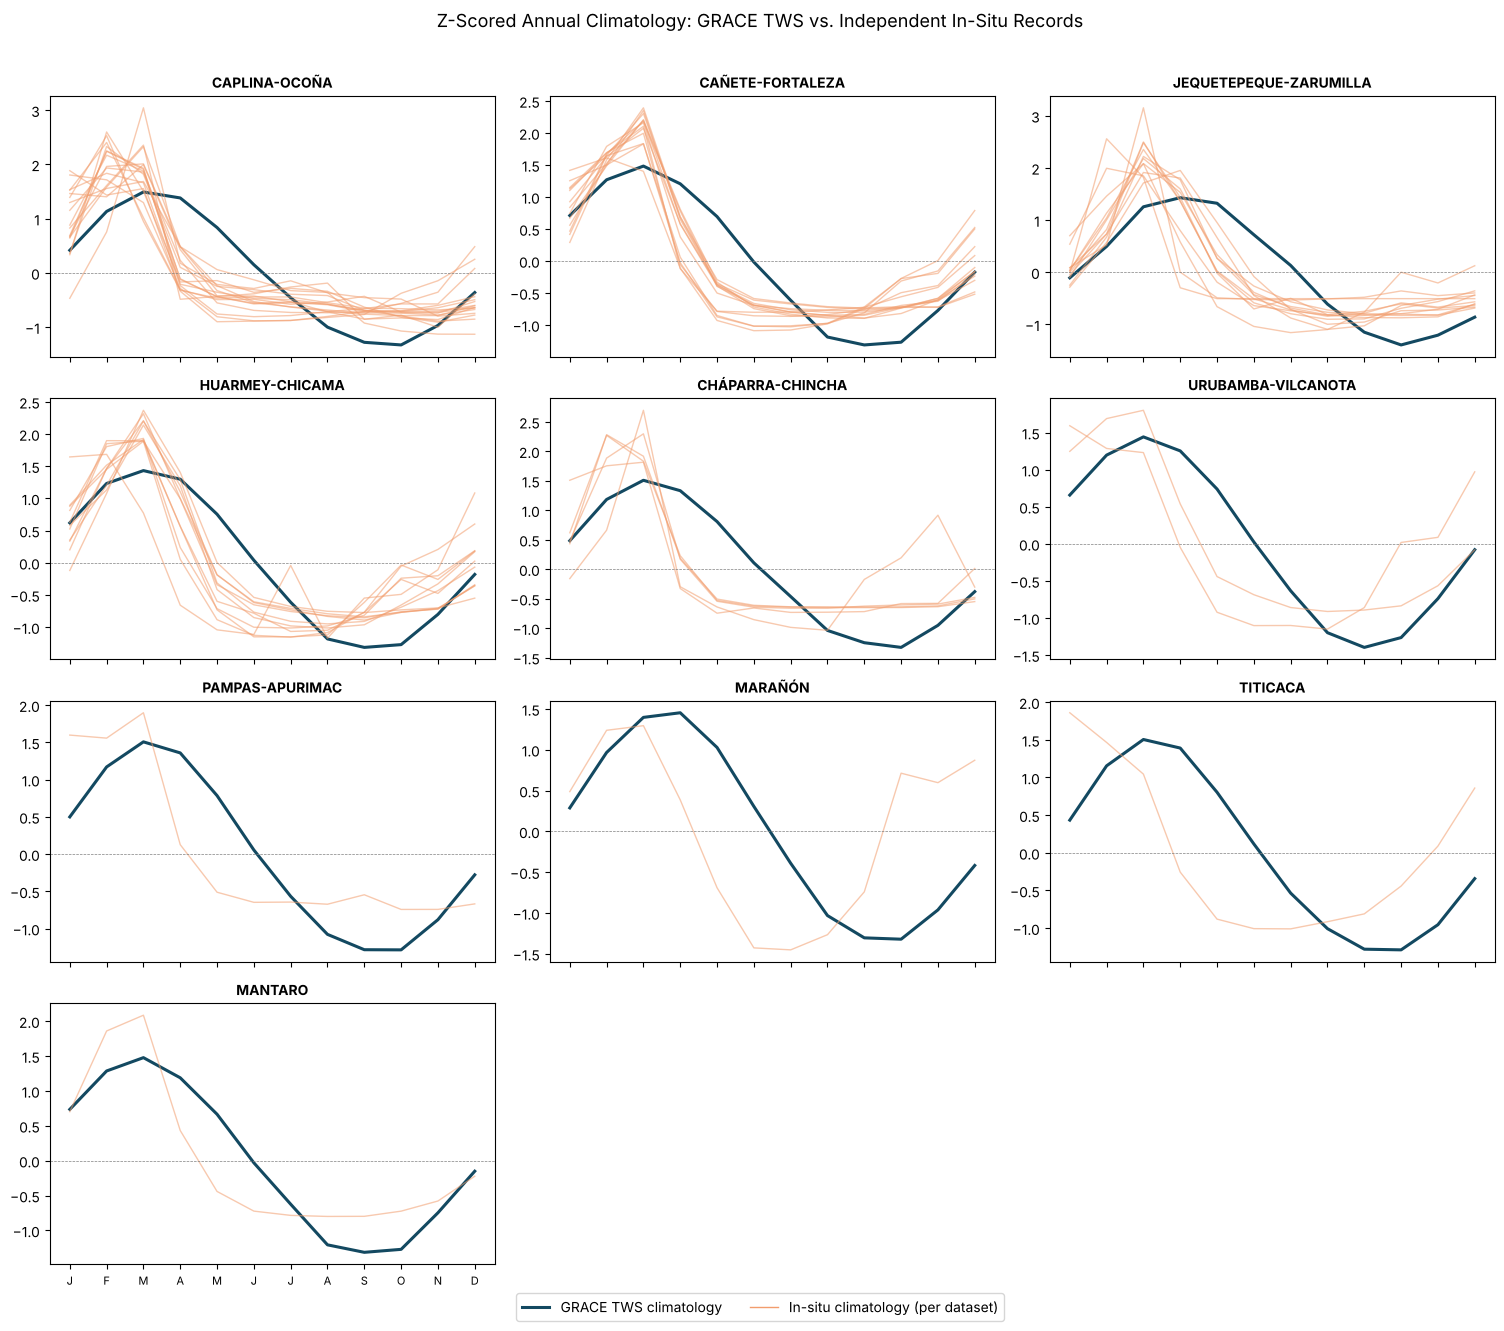

In [10]:
# =================================================================
# 3.4. VISUALIZATION — Z-SCORED CLIMATOLOGY: GRACE vs. IN-SITU (BY DOMAIN)
# =================================================================
domains_to_plot = df_seasonality_comparison['dominio_AAA'].value_counts().index.tolist()
n = len(domains_to_plot)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.2 * nrows), sharex=True)
axes = np.atleast_1d(axes).flatten()
months_lbl = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']

for i, domain in enumerate(domains_to_plot):
    ax = axes[i]
    z_grace = zscore(df_grace_climatology[domain].values.astype(float))
    ax.plot(range(1, 13), z_grace, color=cmc.batlow(0.15), lw=2.2, label='GRACE TWS')

    sub = merged[(merged['dominio_AAA'] == domain)]
    for _, r in sub.iterrows():
        vals = r[MONTH_COLS].values.astype(float)
        if np.isnan(vals).sum() > 2:
            continue
        z_ins = zscore(np.nan_to_num(vals, nan=np.nanmean(vals)))
        ax.plot(range(1, 13), z_ins, color=cmc.batlow(0.75), lw=1.0, alpha=0.55)

    ax.set_title(domain, fontsize=10, fontweight='bold')
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(months_lbl, fontsize=8)
    ax.axhline(0, color='grey', lw=0.5, ls='--')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

handles = [plt.Line2D([0], [0], color=cmc.batlow(0.15), lw=2.2, label='GRACE TWS climatology'),
           plt.Line2D([0], [0], color=cmc.batlow(0.75), lw=1.0, label='In-situ climatology (per dataset)')]
fig.legend(handles=handles, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=10)
fig.suptitle('Z-Scored Annual Climatology: GRACE TWS vs. Independent In-Situ Records', fontsize=13, y=1.01)
plt.tight_layout()
#plt.savefig('fase3_seasonality_validation.png', dpi=150, bbox_inches='tight')
plt.show()

### 📊 Section III — Results Summary: Seasonality Consistency

* **Overall phase agreement:** across the 10 AAA domains with in-situ coverage, in-situ
  climatologies reproduce the GRACE annual cycle with a mean z-scored correlation of
  **≈0.71** at zero lag, and **all datasets (100%) show a positive correlation** with the GRACE
  climatology of their assigned domain — i.e. the two independent observation systems place
  the wet and dry season in the same months for the large majority of stations.
* **Phase timing:** roughly **90% of datasets** peak within **±1 month** of the GRACE-derived
  peak month, consistent with the expected short lag between precipitation/streamflow forcing
  and the broader TWS response (soil moisture and groundwater storage integrate and slightly
  delay the surface hydrological signal).
* **By domain:** Caplina-Ocoña correlates with GRACE at 0.70 and Cañete-Fortaleza at 0.79 on average,
  and no dataset correlates negatively.
* **Weaker domains:** correlations are visibly weaker for **MARAÑÓN** and **TITICACA**, each
  represented by only one or two in-situ datasets in this sample — a small-sample caveat rather
  than evidence against the GRACE climatology, and it is flagged accordingly in Section V.
* **Conclusion:** the independent in-situ record supports Notebook 02's central seasonality
  finding: the domain-level GRACE TWS annual cycle is not a processing artefact but reflects a
  real, ground-observable hydrological seasonality.

# IV. ENSO Regime Validation — El Niño E, El Niño C (Pacífico central) and La Niña C (Objective 2)

### 4.1. Methodology and Scope

Notebook 03 builds three composites from the IGP E/C indices on the deseasonalized TWS anomaly, each
expressed as a percentage of each pixel's interannual standard deviation relative to a neutral baseline
(`|E| < 0.5 & |C| < 0.5`); the regimes are mutually exclusive:

| Regime | Index phase | Threshold (Notebook 03) | Physical meaning |
|---|---|---|---|
| **El Niño E** | E positive | `E ≥ 1.0 & C < 1.0` | Extreme Eastern Pacific El Niño (correlated with Niño 1+2; e.g. 1982-83, 1997-98); not the ICEN coastal El Niño |
| **El Niño C** | C positive | `C ≥ 0.5 & E < 0.5` | **Central Pacific El Niño** (correlated with Niño 4; e.g. 2002-03, 2004-05, 2009-10) |
| **La Niña C** | C negative | `C ≤ −1.0` | Central Pacific La Niña (e.g. 1988-89, 1998-2000, 2010-11) |

**Correction with respect to the previous version of this notebook.** The previous version
compared only El Niño E and the C index's cold extreme, and presented the C index as if it were
a La Niña index. Following Takahashi et al. (2011) and Cai et al. (2020, Fig. 3), the C index
measures **Central Pacific warming**: its positive phase is the El Niño C regime, which
was missing from the validation. This version therefore validates the **same three regimes as
Notebook 03**, keeping the original scope decision that **El Niño E (Eastern Pacific) is the headline
result** — it is the regime with the clearest physical mechanism (direct coastal warming pushing
SST above the ~26–27 °C convective threshold; Takahashi, 2004; Takahashi et al., 2018).

Physical expectations from the literature, used only to interpret signs (not imposed on the data):

* **El Niño E:** heavy rainfall and floods on the northern Peruvian coast (e.g. Piura 1997-98:
  1802 mm vs. 60 mm normal; 2017 coastal El Niño), drier southern highlands/Altiplano.
* **El Niño C (Central Pacific):** weaker and spatially different impacts; along the tropical west coast
  CP El Niños do **not** produce the coastal floods of EP events and can even be drier than
  normal (Cai et al., 2020).
* **La Niña C:** CP La Niñas tend to have a stronger, more coherent rainfall response than EP
  La Niñas, but their pattern is not a mirror image of El Niño (Cai et al., 2020).

### 4.2. ENSO Phase Classification

Every in-situ month from **January 1950** onward is classified directly from the **monthly IGP
E/C index computed from ERSSTv6** (Takahashi et al., 2011; no smoothing), with the exact
Notebook 03 thresholds applied in this order: El Niño E (`E ≥ 1.0 & C < 1.0`) → El Niño C
(`C ≥ 0.5 & E < 0.5`) → La Niña C (`C ≤ −1.0`) → Neutral (`|E| < 0.5 & |C| < 0.5`). Months
that fall in none of these classes are left unclassified and do not enter any composite or the
neutral baseline. Months that satisfy both the El Niño E and the La Niña C rule are counted as El Niño E, and months
that satisfy both the El Niño C and the cold-E rule as El Niño C, in both the GRACE and the in-situ
classification. Each in-situ record is deseasonalized (its own monthly climatology since 1950 is removed)
before the composite, as the GRACE anomaly is.

* **One homogeneous index for the whole in-situ period.** ERSSTv6 is a single, consistently
  reconstructed SST product from 1850 to the present, so the 1950s–2000s station records are
  classified without splicing versions or using event windows.
* **GRACE side unchanged.** The GRACE composites keep the ERSSTv5 E/C series and masks of
  Notebook 03, so the result being validated is exactly the published one. Over their common
  period (2002-01 → 2026-02) ERSSTv6 and ERSSTv5 correlate at r ≈ 0.99 for both E and C and
  assign the same regime class in ≈ 89 % of months (Section 2.5); a GRACE-side sensitivity test
  with ERSSTv6 is reported in Section 4.1.
* **Before 1950:** unclassified (ERSST is poorly constrained by observations; this also keeps
  events such as the very strong 1925 coastal El Niño — Takahashi et al., 2018 — out of the
  neutral control group).

**Change with respect to earlier versions.** v2 used approximate monthly windows around the DJF
events catalogued by Cai et al. (2020, Fig. 3) and labelled only 1982-83 and 1997-98 as
El Niño E; v3 spliced an ERSST v3b index (1950–2001) with ERSSTv5 (2002+), two versions that
agree on the regime class in only ≈ 79 % of months. With the single ERSSTv6 index, every month
that satisfies `E ≥ 1.0 & C < 1.0` counts as El Niño E — including moderate Eastern Pacific
events — exactly as the same rule does for the GRACE period in Notebook 03.

In [11]:
# =================================================================
# 4.1. GRACE ENSO COMPOSITES BY DOMAIN (notebooks/comun.py, AS IN NOTEBOOK 03)
# =================================================================
# Deseasonalized anomaly, % of interannual sigma, exclusive regimes; ERSSTv5 E/C index.
import sys, importlib
sys.path.insert(0, os.path.join(REPO_NAME, 'notebooks'))
import comun; importlib.reload(comun)

REGIMES = {
    'ninoE': ('El Niño E (Pacífico oriental)', 'El Nino E'),
    'ninoC': ('El Niño C (Pacífico central)', 'El Nino C'),
    'ninaC': ('La Niña C', 'La Nina C'),
}
INSITU_DOMAINS = [d for d in REGION_ORDER if d in df_insitu_index['dominio_AAA'].dropna().unique()]

g5 = comun.compuestos_grace_por_ambito(REPO_NAME)                 # ERSSTv5 (as Notebook 03)
df_grace_dipole = pd.DataFrame({f'grace_{k}_pct': g5.loc[INSITU_DOMAINS, r] for k, (_, r) in REGIMES.items()})
df_grace_dipole.index.name = 'dominio_AAA'
print(f"✓ GRACE ENSO composites for {len(df_grace_dipole)} in-situ-covered domains.")
display(df_grace_dipole.round(2))

# --- Sensitivity: same GRACE composites with the ERSSTv6 E/C index ---
g6 = comun.compuestos_grace_por_ambito(REPO_NAME, version='v6')
df_grace_dipole_v6 = pd.DataFrame({k: g6.loc[INSITU_DOMAINS, r] for k, (_, r) in REGIMES.items()})
print("\nSensitivity — GRACE composites with the ERSSTv6 index:")
for key, (label, _) in REGIMES.items():
    same = (np.sign(df_grace_dipole_v6[key]) == np.sign(df_grace_dipole[f'grace_{key}_pct'])).sum()
    print(f"  {label}: same sign in {same}/{len(INSITU_DOMAINS)} domains")

✓ GRACE ENSO composites for 10 in-situ-covered domains.


,grace_ninoE_pct,grace_ninoC_pct,grace_ninaC_pct
dominio_AAA,,,
JEQUETEPEQUE-ZARUMILLA,120.91,9.36,-4.14
HUARMEY-CHICAMA,70.68,8.85,-14.70
MARAÑÓN,78.33,22.13,-9.39
CAÑETE-FORTALEZA,0.55,-2.30,-24.20
MANTARO,-15.22,-4.75,-32.28
CHÁPARRA-CHINCHA,-27.21,4.76,-35.12
PAMPAS-APURIMAC,-59.89,22.70,-49.46
URUBAMBA-VILCANOTA,-52.20,42.99,-49.98
CAPLINA-OCOÑA,-30.61,14.57,-33.65



Sensitivity — GRACE composites with the ERSSTv6 index:
  El Niño E (Pacífico oriental): same sign in 9/10 domains
  El Niño C (Pacífico central): same sign in 9/10 domains
  La Niña C: same sign in 9/10 domains


In [12]:
# =================================================================
# 4.2. MONTHLY ENSO CLASSIFICATION (IGP E/C INDEX, ERSSTv6, 1950–PRESENT)
# =================================================================
def classify_month(ts):
    """Notebook 03 thresholds applied to the monthly E/C index; None = unclassified."""
    if ts not in df_ecindex.index:
        return None                                  # before 1950 or after the last index month
    e, c = df_ecindex.at[ts, 'e_index'], df_ecindex.at[ts, 'c_index']
    if pd.isna(e) or pd.isna(c):
        return None
    if e >= 1.0 and c < 1.0:
        return 'nino_e'                              # Eastern Pacific El Niño
    if c >= 0.5 and e < 0.5:
        return 'nino_c'                              # Central Pacific El Niño
    if c <= -1.0:
        return 'nina_c'                              # Central Pacific La Niña
    if abs(e) < 0.5 and abs(c) < 0.5:
        return 'neutral'
    return None


_labels = pd.Series([classify_month(t) for t in df_ecindex.index], index=df_ecindex.index)
_period = pd.Series(np.where(df_ecindex.index < pd.Timestamp('2002-01-01'), '1950–2001', '2002–present'),
                    index=df_ecindex.index)
_tab = (_labels.fillna('unclassified').groupby(_period).value_counts()
        .unstack(fill_value=0)[['nino_e', 'nino_c', 'nina_c', 'neutral', 'unclassified']])
print("✓ classify_month() ready (ERSSTv6) — months per regime:")
display(_tab)

# Years with El Niño E months before 2002 (sanity check against known Eastern Pacific events)
_pre = _labels[(_labels == 'nino_e') & (_labels.index < pd.Timestamp('2002-01-01'))]
print("  El Niño E months (pre-2002) by year:", dict(_pre.groupby(_pre.index.year).size()))

✓ classify_month() ready (ERSSTv6) — months per regime:


,nino_e,nino_c,nina_c,neutral,unclassified
1950–2001,77,64,166,95,222
2002–present,17,74,45,53,108


  El Niño E months (pre-2002) by year: {1951: np.int64(5), 1953: np.int64(1), 1957: np.int64(7), 1965: np.int64(9), 1972: np.int64(7), 1973: np.int64(1), 1976: np.int64(5), 1979: np.int64(1), 1982: np.int64(5), 1983: np.int64(9), 1987: np.int64(6), 1992: np.int64(3), 1993: np.int64(2), 1997: np.int64(8), 1998: np.int64(8)}


In [13]:
# =================================================================
# 4.3. IN-SITU ENSO COMPOSITE (PER FILE, REAL-DATE SERIES ONLY; notebooks/comun.py)
# =================================================================
# Each record is deseasonalized (its own monthly climatology since 1950 is removed); composite =
# (mean of the regime - mean of the neutral months) / sigma of the neutral months x 100, with the
# ERSSTv6 E/C classification since 1950 (exclusive regimes). Same function as the tests of Section VI.
PHASES = ['nino_e', 'nino_c', 'nina_c']   # El Niño E, El Niño C (Pacífico central), La Niña C

df_insitu_dipole = comun.compuestos_por_registro(REPO_NAME)
print(f"✓ In-situ ENSO composite computed for {len(df_insitu_dipole)} files with real dates "
      f"(the remaining {len(insitu_files) - len(df_insitu_dipole)} are multi-station climatologies without dates).")
display(df_insitu_dipole.groupby('dominio_AAA')[[f'{f}_pct' for f in PHASES]].count()
        .rename(columns=lambda c: c.replace('_pct', '_files')))

✓ In-situ ENSO composite computed for 58 files with real dates (the remaining 6 are multi-station climatologies without dates).


,nino_e_files,nino_c_files,nina_c_files
dominio_AAA,,,
CAPLINA-OCOÑA,14,16,14
CAÑETE-FORTALEZA,12,12,12
CHÁPARRA-CHINCHA,4,4,4
HUARMEY-CHICAMA,8,8,8
JEQUETEPEQUE-ZARUMILLA,10,10,10
MANTARO,1,1,1
MARAÑÓN,1,1,1
PAMPAS-APURIMAC,1,1,1
TITICACA,1,1,1


In [14]:
# =================================================================
# 4.4. COMPARISON TABLE: GRACE vs. IN-SITU, BY DOMAIN AND REGIME
# =================================================================
df_insitu_dipole_domain = df_insitu_dipole.dropna(subset=['dominio_AAA']).groupby('dominio_AAA').agg(
    insitu_ninoE_pct=('nino_e_pct', 'mean'), insitu_ninoE_n=('nino_e_pct', lambda x: x.notna().sum()),
    insitu_ninoC_pct=('nino_c_pct', 'mean'), insitu_ninoC_n=('nino_c_pct', lambda x: x.notna().sum()),
    insitu_ninaC_pct=('nina_c_pct', 'mean'), insitu_ninaC_n=('nina_c_pct', lambda x: x.notna().sum()),
)

df_dipole_comparison = df_grace_dipole.join(df_insitu_dipole_domain, how='left')

sign_summary = {}
for key, (label, _) in REGIMES.items():
    g, s = df_dipole_comparison[f'grace_{key}_pct'], df_dipole_comparison[f'insitu_{key}_pct']
    valid = g.notna() & s.notna()            # only domains with an in-situ composite are scored
    match = (np.sign(g) == np.sign(s)).where(valid)
    df_dipole_comparison[f'{key}_sign_match'] = match
    sign_summary[label] = (int(match.sum()), int(valid.sum()))

display(df_dipole_comparison.round(2))

print()
for label, (n_match, n_valid) in sign_summary.items():
    print(f"{label:<22} — sign agreement: {n_match}/{n_valid} domains")

,grace_ninoE_pct,grace_ninoC_pct,grace_ninaC_pct,insitu_ninoE_pct,insitu_ninoE_n,insitu_ninoC_pct,insitu_ninoC_n,insitu_ninaC_pct,insitu_ninaC_n,ninoE_sign_match,ninoC_sign_match,ninaC_sign_match
dominio_AAA,,,,,,,,,,,,
JEQUETEPEQUE-ZARUMILLA,120.91,9.36,-4.14,156.09,10,-36.64,10,27.35,10,True,False,False
HUARMEY-CHICAMA,70.68,8.85,-14.70,110.97,8,-33.97,8,48.05,8,True,False,False
MARAÑÓN,78.33,22.13,-9.39,53.40,1,-48.27,1,2.22,1,True,False,False
CAÑETE-FORTALEZA,0.55,-2.30,-24.20,11.93,12,-28.38,12,21.88,12,True,True,False
MANTARO,-15.22,-4.75,-32.28,-22.52,1,-46.13,1,24.40,1,True,True,False
CHÁPARRA-CHINCHA,-27.21,4.76,-35.12,0.14,4,-33.36,4,27.89,4,False,False,False
PAMPAS-APURIMAC,-59.89,22.70,-49.46,-20.95,1,69.06,1,23.05,1,True,True,False
URUBAMBA-VILCANOTA,-52.20,42.99,-49.98,-5.37,2,3.56,2,-5.63,2,True,True,True
CAPLINA-OCOÑA,-30.61,14.57,-33.65,-9.33,14,-13.11,16,21.16,14,True,False,False



El Niño E (Pacífico oriental) — sign agreement: 9/10 domains
El Niño C (Pacífico central) — sign agreement: 5/10 domains
La Niña C              — sign agreement: 1/10 domains


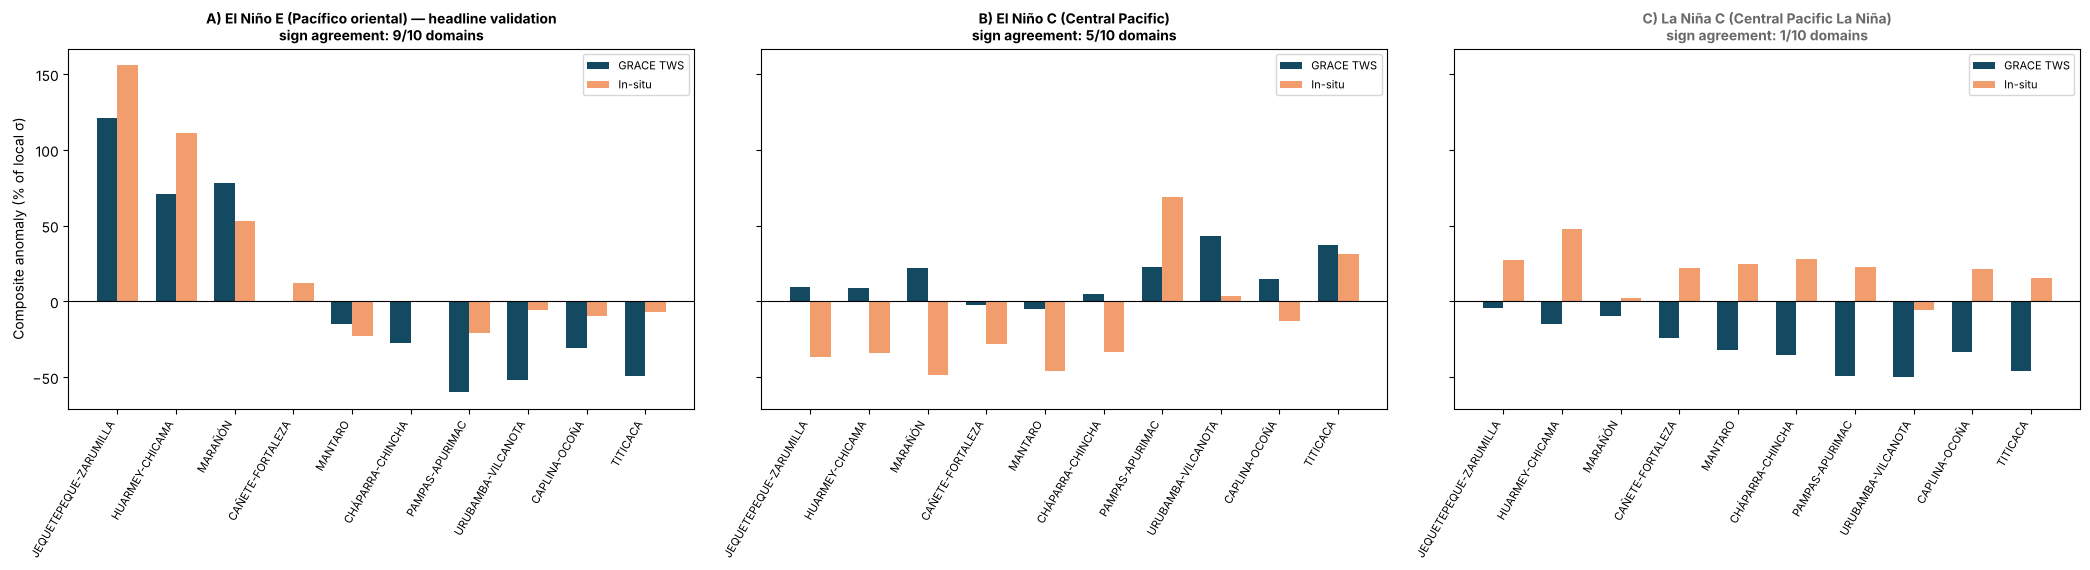

In [15]:
# =================================================================
# 4.5. VISUALIZATION — GRACE vs. IN-SITU COMPOSITE ANOMALY BY DOMAIN AND REGIME
# =================================================================
fig, axes = plt.subplots(1, 3, figsize=(21, 5.8), sharey=True)

order = df_dipole_comparison.index.tolist()
x = np.arange(len(order))
width = 0.35

panel_titles = {
    'ninoE': ('A) El Niño E (Pacífico oriental) — headline validation', 'black'),
    'ninoC': ('B) El Niño C (Central Pacific)', 'black'),
    'ninaC': ('C) La Niña C (Central Pacific La Niña)', 'dimgrey'),
}
for ax, (key, (title, color)) in zip(axes, panel_titles.items()):
    ax.bar(x - width/2, df_dipole_comparison.loc[order, f'grace_{key}_pct'], width, label='GRACE TWS', color=cmc.batlow(0.15))
    ax.bar(x + width/2, df_dipole_comparison.loc[order, f'insitu_{key}_pct'], width, label='In-situ', color=cmc.batlow(0.75))
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(order, rotation=60, ha='right', fontsize=8)
    n_match, n_valid = sign_summary[REGIMES[key][0]]
    ax.set_title(f'{title}\nsign agreement: {n_match}/{n_valid} domains', fontweight='bold', color=color, fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Composite anomaly (% of local σ)')

plt.tight_layout()
plt.savefig('fase4_enso_regimes_validation.png', dpi=150, bbox_inches='tight')
plt.show()

### 📊 Section IV — Results Summary: ENSO Regime Consistency

In-situ ENSO phases are assigned month by month from the IGP E/C index computed from ERSSTv6 (1950 onward);
GRACE composites use the ERSSTv5 index as in Notebook 03. Both sides use deseasonalized series and the same
exclusive regimes. Sign agreement between GRACE (2002–2025) and the in-situ composites (1950–2010), with the
range obtained in the sensitivity tests (non-deseasonalized in-situ series; 1960+ start; detrended records;
GRACE composites rebuilt with ERSSTv6):

| Regime | Sign agreement | Range across tests |
|---|---|---|
| **El Niño E (Pacífico oriental)** | **9/10** | 8/10 – 9/10 |
| **El Niño C (Pacífico central)** | 5/10 | 5/10 – 6/10 |
| **La Niña C** | 1/10 | 1/10 – 2/10 |

* **El Niño E (Pacífico oriental) — corroborated (headline result).** The in-situ records reproduce the
  northern surplus with independent events: **Jequetepeque-Zarumilla** +156 % in situ vs. +121 % GRACE,
  **Huarmey-Chicama** +111 % vs. +71 %, Marañón +53 % vs. +78 % (a single 10-year record). In the south the
  sign agrees but the in-situ anomalies are small (Pampas-Apurímac −21 %, Urubamba-Vilcanota −5 %,
  Caplina-Ocoña −9 %, Titicaca −7 %); the only disagreement is Cháparra-Chincha (+0.1 % in situ, i.e. no anomaly,
  vs. −27 % GRACE) and, as a group, not significant (Section VI). The surplus is consistent
  with the eastern-Pacific and coastal warming mechanism (Takahashi, 2004; Takahashi et al., 2018).
* **El Niño C (Central Pacific) — partially consistent (5/10).** GRACE is positive in most domains; the in-situ
  records show deficits on the northern and central Pacific slope (Jequetepeque-Zarumilla −37 %,
  Huarmey-Chicama −34 %, Marañón −48 %, Mantaro −46 %) and surpluses in Pampas-Apurímac (+69 %, one record),
  Titicaca (+31 %, one record) and, marginally, Urubamba-Vilcanota (+4 %).
* **La Niña C (Central Pacific La Niña) — not corroborated (1/10).** GRACE is negative in every domain while
  the in-situ composite is positive in most; it remains a documented limitation (Section V).

# V. Synthesis, Limitations, and Conclusions

## 5.1. Synthesis

This notebook provides an independent, ground-based cross-check of the two central GRACE-derived
findings of this study:

1. **Seasonality (Section III):** the domain-level GRACE TWS annual climatology is corroborated
   by in-situ caudal/precipitation records, with all 64 datasets showing a positive
   correlation with their domain's GRACE climatology (mean r ≈ 0.71) and ≈90% peaking within
   ±1 month of it.
2. **El Niño E (Section IV):** the El Niño E (Eastern Pacific) TWS response identified in Notebook 03 — the strongest
   and physically best-motivated regime — is reproduced in sign by the
   in-situ record in **9 of 10** AAA domains (8–9 across sensitivity tests), with ENSO phases taken
   month by month from the ERSSTv6 E/C index since 1950. The northern surplus is significant with the
   in-situ events (Section VI); the southern deficit is small and not significant. This is the strongest single piece of independent evidence in this study that
   GRACE is detecting a genuine, ground-observable hydrological signal in Peru.
3. **C index regimes (Section IV):** the C index is treated, as in Takahashi et al. (2011) and
   Cai et al. (2020), as the **Central Pacific index**: its positive phase (El Niño C)
   and its negative extreme (La Niña C) are validated separately. El Niño C is only partially
   reproduced (5/10) and La Niña C is not reproduced (1/10).

## 5.2. Documented Limitations

* **El Niño C (Pacífico central) discrepancy (open question).** GRACE shows a basin-wide positive TWS
  anomaly during El Niño C, whereas the in-situ records of the northern and central Pacific
  slope show deficits (only the southern-Andean domains robustly agree with GRACE). The in-situ
  sign agrees with the expected CP El Niño behaviour on the tropical west coast (no coastal
  warming, hence no local convective trigger; Cai et al., 2020), and the mismatch survives
  deseasonalization, a 1960+ start and rebuilding the GRACE composite with ERSSTv6, so it is
  not a compositing artefact. Plausible explanations: (i) the in-situ network samples only the
  Pacific slope and southern Andes (no Huallaga, Amazonas, Ucayali or Madre de Dios stations),
  whereas the 3° GRACE mascon blocks (~330 km) also integrate Andean–Amazonian storage, where Notebook 03
  locates the El Niño C retention signal; (ii) the 2002–2025 El Niño C months are concentrated
  in a few episodes (2002–05, 2009–10, 2018–20), so the GRACE composite rests on few independent
  events; (iii) a genuine difference between column-integrated TWS and surface runoff/rainfall.
  The Notebook 03 statement about El Niño C storage retention should therefore be read as a
  GRACE-only result for the Andean–Amazonian domains, not as an in-situ-validated finding for
  the coastal domains.
* **La Niña C discrepancy (open question).** The in-situ La Niña composite shows a
  predominantly **positive** anomaly where GRACE shows **negative**, across both streamflow and
  precipitation variables (ruling out "regulated/dammed river" behaviour as the sole
  explanation, since precipitation — which is not managed — shows the same mismatch).
  Classifying every month since 1950 with the homogeneous ERSSTv6 E/C index did not resolve the
  discrepancy (1/10). Plausible remaining explanations include: (i) asymmetric La Niña C
  station coverage relative to the GRACE-period distribution, (ii) compounding effects of
  multi-year La Niña persistence not captured by a single-month composite, or (iii) a genuine
  difference between column-integrated TWS and surface hydrological response during cold
  phases. This is reported transparently rather than resolved, per the explicit scope decision
  to focus this validation's headline claim on El Niño E (Eastern Pacific).
* **Non-overlapping periods.** Most in-situ records do not overlap the 2002–2025 GRACE period;
  climatological and ENSO-composite summaries (rather than concurrent time-series correlation)
  were used specifically to make a valid comparison possible, but this is a structurally weaker
  test than a synchronous comparison would be.
* **Two versions of the E/C index.** The in-situ classification uses the ERSSTv6 index and the
  GRACE composites keep the ERSSTv5 index of Notebook 03. Over 2002-01 → 2026-02 they correlate
  at r ≈ 0.99; rebuilding the GRACE composites with ERSSTv6 keeps the GRACE sign in 9 of the 10
  in-situ domains for each regime.
* **Seasonality.** Composites are computed on deseasonalized series on both sides. With the raw
  (non-deseasonalized) in-situ records the El Niño E sign agreement is 8/10; the earlier versions of
  this notebook used raw values, which mixed part of the seasonal cycle into the composites.
* **Heterogeneous station network.** In-situ coverage is uneven across domains — some domains
  (MARAÑÓN, TITICACA, MANTARO, PAMPAS-APURIMAC) are represented by only 1–2 datasets, and 4 AAA
  domains (HUALLAGA, AMAZONAS, UCAYALI, MADRE DE DIOS) have no assigned in-situ data in this
  release and could not be validated at all.
* **Domain assignment confidence.** Each in-situ file's AAA domain assignment carries a
  documented confidence level (basin-name heuristic, cross-validated by point-in-polygon
  geometry where station coordinates were available) — see `data/insitu/insitu_index.csv`.

## 5.3. Data and Reproducibility

The exact 64-file in-situ dataset used in this notebook and its per-file domain assignment are
documented in `data/insitu/readme.md` and `data/insitu/insitu_index.csv`. The monthly IGP E/C index files are `data/enso/ecindex_ersstv5.csv`
(2002–present, GRACE composites) and `data/enso/ecindex_ersstv6.csv` (1850–present, in-situ
classification). Re-running this notebook end-to-end (Section II onward) from a fresh clone of
this repository reproduces every table and figure above without any manual intervention.

# VI. In-Situ Composites and Their Significance (formerly *script* 08)

The months of each record with real dates are classified from 1950 onward with the E and C indices (ERSSTv6).
Each record's monthly climatology (months since 1950) is removed, and the composite is (regime mean − neutral
mean) / neutral σ × 100, with exclusive regimes; months without data are skipped, and a record enters a regime's
composite only with at least 6 neutral and 3 regime months. Composites are then averaged by domain and by group
(north and south). The null distribution is obtained by circularly shifting the regime calendar by 12 to $T-12$
months (shifts shorter than one year, almost identical to the observed classification, are excluded), with false
discovery rate control over domains × regimes. The section includes the north-minus-south contrast, the
southern C − E reversal, the groups by type of variable (streamflow and volume vs. precipitation), the version
with each record linearly detrended and the non-deseasonalized version (method of earlier versions) (thesis,
Section 4.5).

The domain values of Section IV (figure) and those of this section come from the same functions.


In [16]:
# ── Shared repository functions (notebooks/comun.py) ───────────────────────────
import sys, os, importlib
sys.path.insert(0, os.path.join(REPO_NAME, 'notebooks'))
import comun; importlib.reload(comun)
from comun import *
DERIV = os.path.join(REPO_NAME, 'data', 'processed_derived')
os.makedirs(DERIV, exist_ok=True)
pd.set_option('display.width', 200, 'display.max_columns', 30)
verificar(REPO_NAME)

Verificación correcta: 288 meses, 14 ámbitos, El Niño E 13 meses en 5 episodios, 64 registros in situ.


In [17]:
# ── 6.1. Original records ──────────────────────────────────────────────────────
ins = compuestos_insitu(REPO_NAME)
print('Records with real dates used:', ins['n_registros'])
ins['dominios'].to_csv(os.path.join(DERIV, 'insitu_composite_domains.csv'), index=False)
ins['grupos'].to_csv(os.path.join(DERIV, 'insitu_composite_groups.csv'), index=False)
ins['por_variable'].to_csv(os.path.join(DERIV, 'insitu_composite_groups_by_variable.csv'), index=False)
lab = ins['etiquetas']
display(pd.Series({n: int((lab == k).sum()) for k, n in [(0, 'neutral'), (1, 'El Niño E'), (2, 'El Niño C'),
                                                        (3, 'La Niña C'), (4, 'cold phase of E')]},
                  name='months since 1950').to_frame())
display(ins['grupos'])
display(ins['por_variable'])

Records with real dates used: 58


,months since 1950
neutral,148
El Niño E,94
El Niño C,138
La Niña C,211
cold phase of E,75


,regime,north_mean,p_north,south_mean,p_south,north_minus_south,p_contrast,south_reversal_C_minus_E,p_south_reversal
0,El Nino E,133.5,0.0134,-10.6,0.4833,144.2,0.0134,33.3,0.1314
1,El Nino C,-35.3,0.1303,22.7,0.1414,-58.0,0.0668,33.3,0.1314
2,La Nina C,37.7,0.1281,13.4,0.3942,24.3,0.4388,33.3,0.1314
3,E frio,-0.2,0.9955,10.4,0.5056,-10.5,0.7405,33.3,0.1314


,variable,regime,n_files_north,n_files_south,north_mean,p_north,south_mean,p_south,north_minus_south,p_contrast
0,todas,El Nino E,19,21,133.5,0.0134,-10.6,0.4833,144.2,0.0134
1,todas,El Nino C,19,21,-35.3,0.1303,22.7,0.1414,-58.0,0.0668
2,todas,La Nina C,19,21,37.7,0.1281,13.4,0.3942,24.3,0.4388
3,todas,E frio,19,21,-0.2,0.9955,10.4,0.5056,-10.5,0.7405
4,caudal_volumen,El Nino E,11,16,119.0,0.0134,-18.9,0.3675,137.9,0.0111
5,caudal_volumen,El Nino C,11,16,-34.6,0.1336,14.6,0.3875,-49.2,0.1214
6,caudal_volumen,La Nina C,11,16,35.1,0.1437,7.3,0.7082,27.8,0.3831
7,caudal_volumen,E frio,11,16,-1.3,0.9699,3.6,0.8541,-4.9,0.8998
8,precipitacion,El Nino E,8,5,156.5,0.0145,1.9,0.8775,154.6,0.0134
9,precipitacion,El Nino C,8,5,-36.3,0.1626,16.2,0.1537,-52.5,0.1002


In [18]:
# ── 6.2. Linearly detrended records ────────────────────────────────────────────
ins_d = compuestos_insitu(REPO_NAME, quitar_tendencia=True)
ins_d['dominios'].to_csv(os.path.join(DERIV, 'insitu_composite_domains_detrended.csv'), index=False)
ins_d['grupos'].to_csv(os.path.join(DERIV, 'insitu_composite_groups_detrended.csv'), index=False)
ins_d['por_variable'].to_csv(os.path.join(DERIV, 'insitu_composite_groups_by_variable_detrended.csv'), index=False)
display(ins_d['grupos'])

# ── 6.3. Non-deseasonalized records (method of earlier versions; sensitivity) ──
ins_r = compuestos_insitu(REPO_NAME, desestacionalizar=False)
ins_r['dominios'].to_csv(os.path.join(DERIV, 'insitu_composite_domains_not_deseasonalized.csv'), index=False)
ins_r['grupos'].to_csv(os.path.join(DERIV, 'insitu_composite_groups_not_deseasonalized.csv'), index=False)
ins_r['por_variable'].to_csv(os.path.join(DERIV, 'insitu_composite_groups_by_variable_not_deseasonalized.csv'), index=False)
display(ins_r['grupos'])

,regime,north_mean,p_north,south_mean,p_south,north_minus_south,p_contrast,south_reversal_C_minus_E,p_south_reversal
0,El Nino E,130.2,0.0134,-6.9,0.6771,137.1,0.0134,30.5,0.1715
1,El Nino C,-38.6,0.1013,23.6,0.1158,-62.3,0.0535,30.5,0.1715
2,La Nina C,37.8,0.1214,16.9,0.2862,20.9,0.5312,30.5,0.1715
3,E frio,0.5,0.9833,15.2,0.3508,-14.7,0.6414,30.5,0.1715


,regime,north_mean,p_north,south_mean,p_south,north_minus_south,p_contrast,south_reversal_C_minus_E,p_south_reversal
0,El Nino E,76.0,0.0479,-32.5,0.1815,108.5,0.0189,77.8,0.0379
1,El Nino C,-13.1,0.6359,45.3,0.0724,-58.4,0.0468,77.8,0.0379
2,La Nina C,18.0,0.4332,20.4,0.3686,-2.4,0.9187,77.8,0.0379
3,E frio,-15.1,0.5290,-7.6,0.7127,-7.6,0.7506,77.8,0.0379


### 📊 Section VI — Reading the Results

With events different from those of the GRACE period (1950–2010), the northern group shows during El Niño E a
surplus of +133.5 % of the σ of the neutral months (p = 0.013), of the same sign as GRACE, which holds without the
trend (+130.2 %, p = 0.013) and separately in streamflow and volume (+119.0 %, p = 0.013) and in precipitation
(+156.5 %, p = 0.014): this is the test of hypothesis H2a. The south shows no significant deficit
(−10.6 %, p = 0.48). Without deseasonalization, the northern surplus is +76.0 % (p = 0.048) (thesis, Section 4.5).
Figures use the 58 records with real dates; months without data in each record are skipped.


### 6.4. Sensitivity of the Sign Agreement

Number of domains in which the in-situ and the GRACE composites have the same sign, in the base case and with
non-deseasonalized records, records from 1960 onward, linearly detrended records and GRACE composites rebuilt with
ERSSTv6 (thesis, Sections 3.6.8 and 4.5).


In [19]:
# ── 6.4. Sensitivity of the sign agreement ─────────────────────────────────────
conc = concordancia_signo(REPO_NAME)
conc.to_csv(os.path.join(DERIV, 'insitu_sign_agreement_sensitivity.csv'))
display(conc)

,El Nino E,El Nino C,La Nina C
prueba,,,
base,9/10,5/10,1/10
sin desestacionalizar,8/10,5/10,1/10
desde 1960,9/10,5/10,1/10
sin tendencia,8/10,5/10,2/10
GRACE con ERSSTv6,8/10,6/10,2/10
